# Can a small model beat the Polymarket price?

Notebook 01 found a market that is fast and well calibrated. Here we try to beat it: predict whether Up wins, on the six 5-minute series of 2026-10-20, using a handful of features and LightGBM. The benchmark is the Polymarket mid itself.

**Result: no.** None of the 64 LightGBM configurations beat the market mid on the 144 BTC test markets, and nor did the baselines. The closest selected model, a correction to the price trained on all six coins, scored a Brier of 0.1393 against the market's 0.1377. Its gap of +0.0017 has a 95% interval of -0.0027 to +0.0063, so it is a statistical tie with the price.

**What did matter:**

- **Training on all six coins** beat training on BTC alone for every feature set.
- **The oracle** was worth far more than any exchange feature.
- **Hyperparameters** barely moved the result.

This is a demonstration on one day and not a trading signal. Brier scores ignore spread, fees and fills.

**Data:** the [free sample](https://huggingface.co/datasets/RabbitGo777/polymarket.btc_20261020.v4.1s.parquet) on Hugging Face, downloaded by the first cell.

In [1]:
import sys
from itertools import product
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from pmlab.data import COINS, ROOT, download_agg
from pmlab.features import build_features
from pmlab.models import FEATURE_SETS, FOLDS, fit, predict, score, split
from pmlab.plots import BLUE, INK_2, MUTED, ORANGE, apply_style, save
from pmlab.stats import brier

apply_style()
pd.set_option("display.max_columns", 30, "display.width", 140)
download_agg()

In [2]:
data = pd.concat([build_features(c) for c in COINS], ignore_index=True)
data["digital"] = data["digital"].fillna(0.5)
print(f"{len(data):,} rows, {data['market'].nunique():,} markets, base rate of Up {data.groupby('market')['y'].first().mean():.3f}")
data[FEATURE_SETS["price+correction"][0]].describe().T[["count", "mean", "std", "min", "max"]].round(2)

103,680 rows, 1,728 markets, base rate of Up 0.514


,count,mean,std,min,max
tau_sec,103680.0,152.50,86.59,5.00,300.00
ret_start_bps,103680.0,0.25,11.54,-179.66,106.40
ret_5s_bps,103674.0,0.01,1.94,-29.41,39.46
sigma_60_bps,103656.0,0.66,0.46,0.00,4.85
taker_imb_60,103680.0,-0.02,0.40,-1.00,1.00
oracle_ret_bps,102065.0,0.30,10.73,-162.26,103.39
pm_logit,103680.0,0.02,2.55,-5.29,5.29
pm_spread_c,103680.0,2.03,2.33,0.10,71.00
pm_imb_top,103680.0,-0.04,0.60,-1.00,1.00


## Setup

**Rows.** One row every 5 seconds per market on the Up token, which gives 103,680 rows from 1,728 markets. Rows of one market share one outcome, so the real sample is the number of markets, and because coins move together, closer to the number of opening times.

**Target.** `y = 1` if Up won.

**Features.** All of them use only what was known at the end of the bar they are stamped with. Chainlink values are joined on their arrival time, not on their round time. `tests/test_pmlab.py` checks this.

| Group | Columns |
|---|---|
| Binance perp | `tau_sec`, `ret_start_bps` (return since the market opened), `ret_5s_bps`, `sigma_60_bps`, `taker_imb_60` |
| Chainlink | `oracle_ret_bps` (the 60-second TWAP now against its value at the market's start) |
| Polymarket book | `pm_logit` (the price itself), `pm_spread_c`, `pm_imb_top` |

**Feature sets.** `binance` and `binance+oracle` never see the Polymarket book. `binance+oracle+book` gets the price as a feature. `price+correction` starts each prediction at the market price through LightGBM's `init_score` and learns only an adjustment.

**Validation.** Walk-forward inside the day, with three folds. Train up to hour H-2, stop early on the next two hours, test on the four hours after H, for H = 12, 16 and 20. A market belongs to one part only. Everything from 12:00 onwards is out of sample.

**Search.** Eight parameter sets × four feature sets × two training universes = 64 configurations and 192 fits. One configuration per row is picked by validation log loss, never by test score.

In [3]:
GRID = [dict(num_leaves=a, min_data_in_leaf=b, learning_rate=c) for a, b, c in product((7, 31), (100, 500), (0.02, 0.05))]
UNIVERSES = {"BTC only": data[data["coin"] == "btc"], "all six coins": data}

records, out = [], []
for (universe, frame), (name, (columns, anchored)), params in product(UNIVERSES.items(), FEATURE_SETS.items(), GRID):
    preds = []
    valid_loss = []
    for train_end, test_end in FOLDS:
        tr, va, _ = split(frame, train_end, test_end)
        _, _, te = split(data, train_end, test_end)
        model = fit(frame[tr], frame[va], columns, anchored, params)
        valid_loss.append(model.best_score["valid_0"]["binary_logloss"])
        test = data[te]
        preds.append(pd.Series(predict(model, test, columns, anchored), index=test.index))
    pred = pd.concat(preds)
    records.append({"universe": universe, "features": name, **params, "valid_log_loss": np.mean(valid_loss), "pred": pred})
print(len(records), "configurations,", len(records) * len(FOLDS), "fits")

64 configurations, 192 fits


## Picking one configuration per row, on validation only

In [4]:
grid = pd.DataFrame(records)
test_rows = data.loc[grid["pred"].iloc[0].index]
btc = test_rows[test_rows["coin"] == "btc"]
grid["btc_gap"] = [score(btc, r["pred"].loc[btc.index].to_numpy())["gap_to_mid"] for _, r in grid.iterrows()]
grid.drop(columns="pred").round(5).to_csv(ROOT / "results" / "model_grid.csv", index=False)
chosen = grid.loc[grid.groupby(["universe", "features"], sort=False)["valid_log_loss"].idxmin()]
chosen.drop(columns="pred").set_index(["universe", "features"]).round(5)

num_leaves  min_data_in_leaf  learning_rate  valid_log_loss  btc_gap
universe      features                                                                                 
BTC only      binance                       7               500           0.02         0.48788  0.03095
              binance+oracle                7               100           0.02         0.40745  0.02938
              binance+oracle+book           7               100           0.05         0.35075  0.01435
              price+correction              7               100           0.05         0.34315  0.01095
all six coins binance                       7               500           0.05         0.47385  0.02613
              binance+oracle               31               500           0.02         0.41663  0.01936
              binance+oracle+book           7               500           0.02         0.38100  0.00334
              price+correction             31               500           0.05         0.37528  0.00166

In [5]:
def logistic(frame, columns):
    preds = []
    for train_end, test_end in FOLDS:
        tr, _, _ = split(frame, train_end, test_end)
        _, _, te = split(data, train_end, test_end)
        scale = StandardScaler().fit(frame.loc[tr, columns].fillna(0))
        model = LogisticRegression(C=1.0).fit(scale.transform(frame.loc[tr, columns].fillna(0)), frame.loc[tr, "y"])
        preds.append(pd.Series(model.predict_proba(scale.transform(data.loc[te, columns].fillna(0)))[:, 1], index=data.index[te]))
    return pd.concat(preds)

data["z"] = np.clip(data["ret_start_bps"] / (data["sigma_60_bps"] * np.sqrt(data["tau_sec"])), -8, 8).fillna(0)
data["z_oracle"] = np.clip(data["oracle_ret_bps"] / (data["sigma_60_bps"] * np.sqrt(data["tau_sec"])), -8, 8).fillna(0)
LOGISTIC = ["pm_logit", "z", "z_oracle"]
baselines = {"market mid": data.loc[test_rows.index, "mid"],
             "digital option, no fitting": data.loc[test_rows.index, "digital"],
             "logistic: price + 2 z-scores": logistic(data, LOGISTIC)}

def report(population):
    rows = [{"model": k, "trained on": "-", **score(population, v.loc[population.index].to_numpy())} for k, v in baselines.items()]
    rows += [{"model": f"LightGBM {r['features']}", "trained on": r["universe"], **score(population, r["pred"].loc[population.index].to_numpy())}
             for _, r in chosen.iterrows()]
    return pd.DataFrame(rows).set_index(["model", "trained on"])

btc_report, all_report = report(btc), report(data.loc[test_rows.index])
btc_report.to_csv(ROOT / "results" / "model_scores_btc.csv")
all_report.to_csv(ROOT / "results" / "model_scores_all.csv")
btc_report.round(5)

,,markets,brier,log_loss,auc,gap_to_mid,gap_low,gap_high
model,trained on,,,,,,,
market mid,-,144,0.13765,0.40261,0.88357,0.00000,0.00000,0.00000
"digital option, no fitting",-,144,0.16587,0.52397,0.83788,0.02823,0.00899,0.04747
logistic: price + 2 z-scores,-,144,0.14095,0.41040,0.87959,0.00330,0.00022,0.00675
LightGBM binance,BTC only,144,0.16860,0.50491,0.83101,0.03095,0.01424,0.04772
LightGBM binance+oracle,BTC only,144,0.16703,0.49376,0.84076,0.02938,0.01923,0.03953
LightGBM binance+oracle+book,BTC only,144,0.15199,0.44089,0.86618,0.01435,0.00470,0.02421
LightGBM price+correction,BTC only,144,0.14860,0.42920,0.87104,0.01095,0.00337,0.01897
LightGBM binance,all six coins,144,0.16378,0.48944,0.83950,0.02613,0.01081,0.04140
LightGBM binance+oracle,all six coins,144,0.15700,0.46003,0.85247,0.01936,0.01204,0.02667


In [6]:
all_report.round(5)

,,markets,brier,log_loss,auc,gap_to_mid,gap_low,gap_high
model,trained on,,,,,,,
market mid,-,864,0.13505,0.40091,0.88864,0.00000,0.00000,0.00000
"digital option, no fitting",-,864,0.16152,0.50052,0.84335,0.02647,0.01538,0.03762
logistic: price + 2 z-scores,-,864,0.13659,0.40399,0.88651,0.00154,-0.00006,0.00336
LightGBM binance,BTC only,864,0.16694,0.50201,0.83569,0.03189,0.02009,0.04433
LightGBM binance+oracle,BTC only,864,0.16060,0.49651,0.85303,0.02555,0.01867,0.03255
LightGBM binance+oracle+book,BTC only,864,0.14531,0.43423,0.87716,0.01026,0.00465,0.01654
LightGBM price+correction,BTC only,864,0.14278,0.42309,0.88021,0.00773,0.00294,0.01285
LightGBM binance,all six coins,864,0.16401,0.48913,0.83841,0.02896,0.01841,0.03999
LightGBM binance+oracle,all six coins,864,0.15279,0.45311,0.85872,0.01774,0.01301,0.02241


Both tables score on out-of-sample rows only. The first covers BTC; the second covers all six coins, and the gap column is Brier minus the market's.

- **Nothing beats the price.** Every row has a positive gap on BTC, and only the two pooled models that see the book have an interval that includes zero.
- **The market holds information the features lack.** The closed-form digital option (`Φ(return / (σ√τ))`, on Binance data) scores 0.166 against the market's 0.138. LightGBM on Binance alone does no better.
- **A three-input logistic regression is as good as boosting with the book.** It reaches 0.1410 on BTC against 0.1410 for `binance+oracle+book` pooled, so the extra complexity buys nothing here.
- **More markets help.** Pooling all six coins beat BTC-only training in all four feature sets: gaps of 0.026 vs 0.031, 0.019 vs 0.029, 0.003 vs 0.014, and 0.002 vs 0.011.

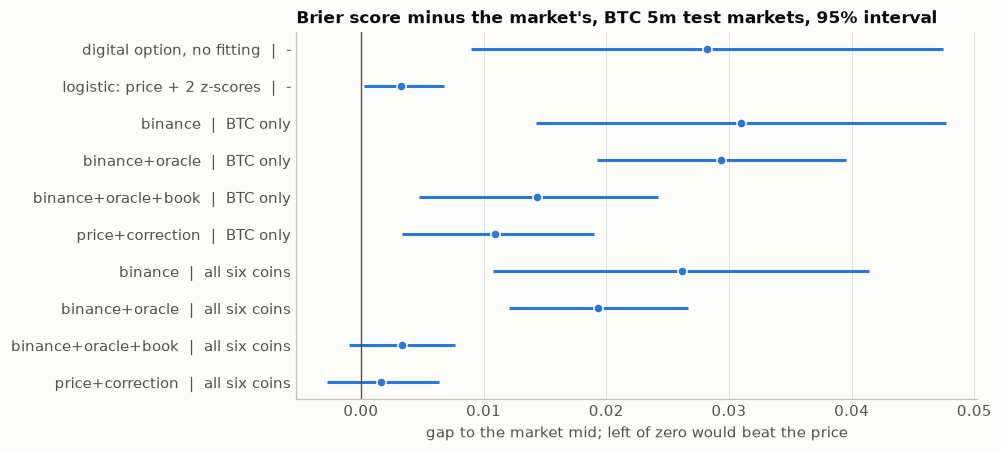

In [7]:
gap = btc_report.drop(index="market mid", level="model").reset_index()
gap = gap.iloc[::-1]
labels = gap["model"].str.replace("LightGBM ", "") + "  |  " + gap["trained on"]
y = np.arange(len(gap))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hlines(y, gap["gap_low"], gap["gap_high"], color=BLUE, lw=2)
ax.plot(gap["gap_to_mid"], y, "o", color=BLUE, ms=6, mec="#fcfcfb", mew=1)
ax.axvline(0, color=INK_2, lw=0.9)
ax.set_yticks(y, labels)
ax.grid(False)
ax.grid(axis="x")
ax.set_title("Brier score minus the market's, BTC 5m test markets, 95% interval")
ax.set_xlabel("gap to the market mid; left of zero would beat the price")
save(fig, "10_model_gap")

Intervals resample whole opening times, so they reflect the 144 test markets and not the 8,640 rows. Two rows include zero, and in both the point estimate is still worse than the price.

## Did the parameters matter?

Every configuration, scored on the BTC test markets. This table is for reading only. Nothing above was chosen from it.

In [8]:
spread = (grid.groupby(["universe", "features"], sort=False)["btc_gap"].agg(best="min", median="median", worst="max")
          .join(chosen.set_index(["universe", "features"])["btc_gap"].rename("selected")))
effects = pd.concat({p: grid.groupby(p)["btc_gap"].mean() for p in ("num_leaves", "min_data_in_leaf", "learning_rate", "universe")}, names=["parameter", "value"]).to_frame("mean_gap")
display(spread.round(5))
effects.round(5)

best   median    worst  selected
universe      features                                                
BTC only      binance              0.03022  0.03103  0.03156   0.03095
              binance+oracle       0.02896  0.02968  0.03146   0.02938
              binance+oracle+book  0.01225  0.01282  0.01666   0.01435
              price+correction     0.00820  0.01063  0.01151   0.01095
all six coins binance              0.02513  0.02577  0.02798   0.02613
              binance+oracle       0.01708  0.01812  0.01936   0.01936
              binance+oracle+book  0.00316  0.00535  0.00717   0.00334
              price+correction     0.00035  0.00074  0.00166   0.00166

mean_gap
parameter        value                  
num_leaves       7               0.01655
                 31              0.01723
min_data_in_leaf 100             0.01693
                 500             0.01686
learning_rate    0.02            0.01685
                 0.05            0.01694
universe         BTC only        0.02119
                 all six coins   0.01260

Parameters hardly moved the score. Across the grid, learning rate and `min_data_in_leaf` shifted the mean gap by less than 0.0001 and `num_leaves` by 0.0007, while the choice of training universe shifted it by 0.0086. **What goes into the model matters far more than how it is tuned.** Even the best test score among the 64 configurations, which could not have been known in advance, stays above the market at +0.0004.

## Where in the market's life

In [9]:
buckets = [(0, 30), (30, 60), (60, 120), (120, 180), (180, 300)]
pick = chosen[(chosen["universe"] == "all six coins") & (chosen["features"] == "binance+oracle")].iloc[0]
pick2 = chosen[(chosen["universe"] == "all six coins") & (chosen["features"] == "price+correction")].iloc[0]
rows = []
for lo, hi in buckets:
    d = btc[(btc["tau_sec"] > lo) & (btc["tau_sec"] <= hi)]
    rows.append({"seconds_left": f"{lo}-{hi}", "rows": len(d), "market mid": brier(d["mid"], d["y"]), "digital": brier(d["digital"].fillna(0.5), d["y"]),
                 "no price": brier(pick["pred"].loc[d.index], d["y"]), "price+correction": brier(pick2["pred"].loc[d.index], d["y"])})
pd.DataFrame(rows).set_index("seconds_left").round(4)

,rows,market mid,digital,no price,price+correction
seconds_left,,,,,
0-30,864,0.0078,0.0801,0.0223,0.0075
30-60,864,0.0309,0.0676,0.0550,0.0309
60-120,1728,0.0921,0.1162,0.1114,0.0935
120-180,1728,0.1503,0.1736,0.1757,0.1503
180-300,3456,0.2132,0.2329,0.2296,0.2168


## What the model uses

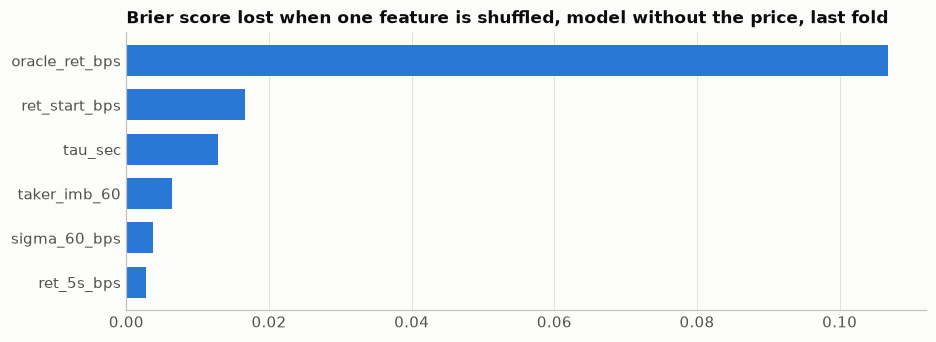

,brier_lost
oracle_ret_bps,0.10674
ret_start_bps,0.01664
tau_sec,0.01280
taker_imb_60,0.00645
sigma_60_bps,0.00368
ret_5s_bps,0.00269


In [10]:
columns, anchored = FEATURE_SETS["binance+oracle"]
params = {k: pick[k] for k in ("num_leaves", "min_data_in_leaf", "learning_rate")}
tr, va, te = split(data, *FOLDS[-1])
model = fit(data[tr], data[va], columns, anchored, params)
test = data[te]
base = brier(predict(model, test, columns, anchored), test["y"])
rng = np.random.default_rng(0)
drop = {}
for c in columns:
    shuffled = test.copy()
    shuffled[c] = rng.permutation(shuffled[c].to_numpy())
    drop[c] = brier(predict(model, shuffled, columns, anchored), test["y"]) - base
drop = pd.Series(drop).sort_values()
fig, ax = plt.subplots(figsize=(8.4, 3))
ax.barh(drop.index, drop, color=BLUE, height=0.7)
ax.grid(False)
ax.grid(axis="x")
ax.set_title("Brier score lost when one feature is shuffled, model without the price, last fold")
save(fig, "11_importance")
drop.sort_values(ascending=False).round(5).to_frame("brier_lost")

The Chainlink feature is the one that counts: shuffling it costs 0.107 of Brier score, six times the next feature. That fits notebook 01, since these markets settle on the oracle and not on Binance. It is also why the digital option on Binance is so far off in the last 30 seconds, at 0.080 against the market's 0.008.

The table above tells the same story from another side. `price+correction` loses most ground in the first two minutes (0.2168 vs 0.2132), stays close after that, and is a hair ahead in the last 30 seconds (0.0075 vs 0.0078), which is far too small to matter on this sample.

## Limits

- **One day.** The test covers 12 hours of one Tuesday, so a good or bad result could be that day's regime.
- **Small sample.** 144 BTC markets is little evidence, and `price+correction` has few outcomes to learn from. The BTC-only version makes the price worse.
- **Few features on purpose.** There are no order-flow, cross-venue or richer oracle features.
- **One-second bars.** Features come from 1 s aggregates, sampled every 5 seconds. They cannot see the 50 to 400 ms reaction that notebook 01 measures on raw ticks, so this says nothing about an edge at that speed.
- **No trading.** A better Brier score would not by itself mean profit after the spread and a 1.75-cent fee.

## Going further

More markets were the clearest gain above, and that is easy to test: the [keydata.shop](https://keydata.shop) archive has every day from 2026-03-24 in the same format, so the same walk-forward can run over days instead of hours. Before 2026-08-14 the 5-minute markets settled on `twap_30s`, so `oracle_ret_bps` must use that column on earlier days. Shorter samples are at [keydata.shop/samples](https://keydata.shop/samples).